# Engineering Tripod

Run all cells in your OneSimulation environment. The recorded output below was generated by executing this code. The spatial view uses the solved forces, eigenvectors or stress tensor.

H=3 kN: signed member forces [kN] [-5.657 -1.414 -1.414]
H=6 kN: signed member forces [kN] [-8.485  0.     0.   ]


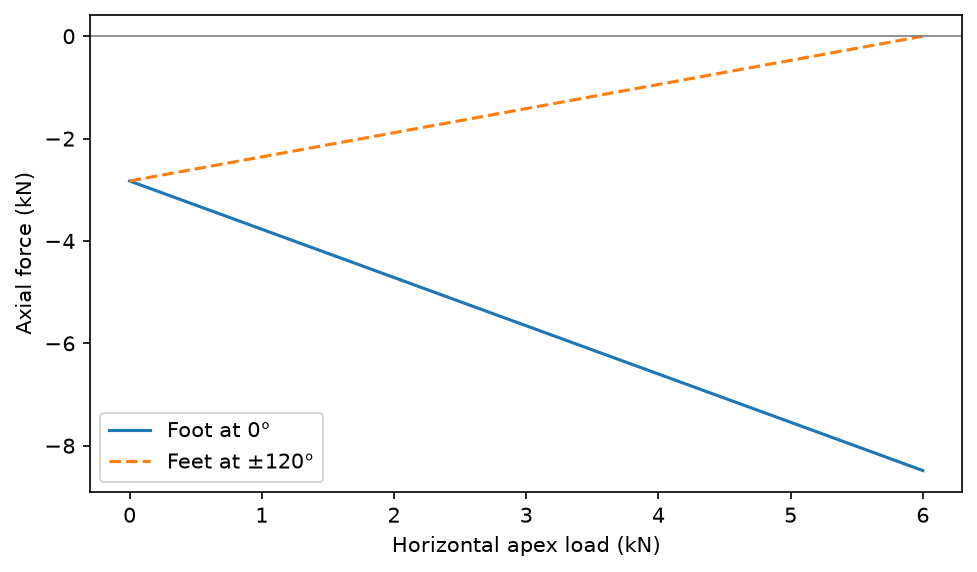

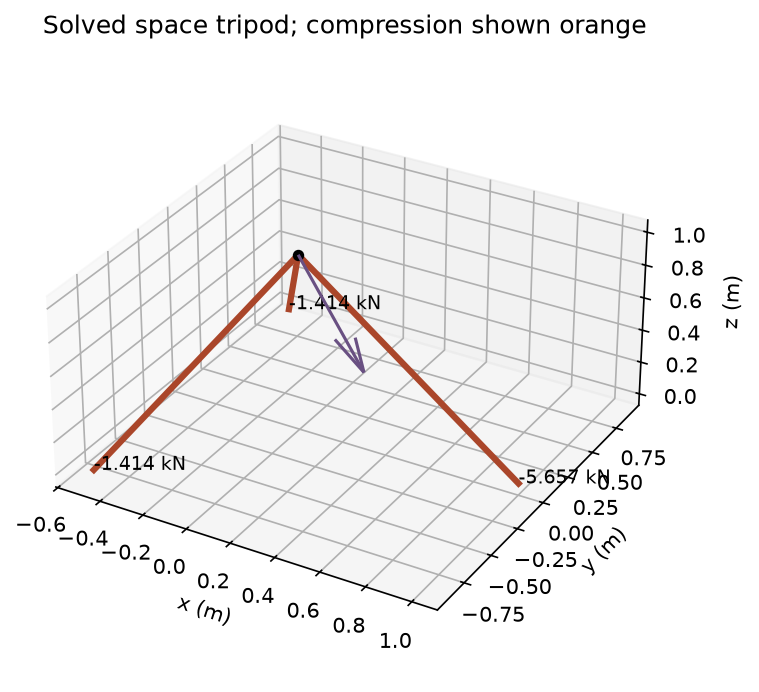

In [1]:
"""Resolve measured loads on a three-dimensional tripod into signed member forces."""
import numpy as np
import matplotlib.pyplot as plt
from onesim.numerics.nonlinear import LeastSquares

angles = np.deg2rad([0, 120, 240])
# Columns point from the loaded apex toward a foot; positive force is tension.
directions = np.array([np.cos(angles), np.sin(angles), -np.ones(3)]) / np.sqrt(2)
horizontal = np.linspace(0, 6, 61)  # kN
forces = []
for load in horizontal:
    external = np.array([load, 0.0, -6.0])
    fit = LeastSquares().solve(lambda force: directions @ force + external, [-2.0]*3)
    assert np.linalg.norm(directions @ fit.x + external) < 1e-6
    forces.append(fit.x)
forces = np.array(forces)
print("H=3 kN: signed member forces [kN]", np.round(forces[30], 3))
print("H=6 kN: signed member forces [kN]", np.round(forces[-1], 3))
fig, ax = plt.subplots(figsize=(6.4, 3.7), layout="constrained")
ax.plot(horizontal, forces[:, 0], label="Foot at 0°")
ax.plot(horizontal, forces[:, 1], "--", label="Feet at ±120°")
ax.axhline(0, color="0.5", lw=0.8)
ax.set(xlabel="Horizontal apex load (kN)", ylabel="Axial force (kN)")
ax.legend()
plt.show()

# Inspect the same solved three-dimensional joint, not an unrelated planar sketch.
fig = plt.figure(figsize=(6,4.5), layout="constrained")
ax = fig.add_subplot(111, projection="3d")
apex = np.array([0.,0.,1.])
feet = np.column_stack((np.cos(angles),np.sin(angles),np.zeros(3)))
selected_forces = forces[30]  # H=3 kN, W=6 kN
for foot, value in zip(feet, selected_forces):
    segment = np.vstack((apex,foot))
    ax.plot(*segment.T, linewidth=3, color="#aa462a" if value<0 else "#19596a")
    ax.text(*foot, f"{value:.3f} kN",fontsize=9)
ax.scatter(*apex, color="black")
ax.quiver(*apex, .3,0,-.6, color="#695082")
ax.set(xlabel="x (m)",ylabel="y (m)",zlabel="z (m)",title="Solved space tripod; compression shown orange")
ax.set_box_aspect((2,2,1))
plt.show()
